# 02 · How many times does a contract get modified? Poisson → Negative Binomial → Zero-inflated NB

**Outcome:** number of modifications after signing (`n_mods`).
**Exposure:** planned length of performance in years at signing, entered as an offset (`log_planned_years`). A
five-year contract has more chances to be modified than a three-month one, so we model the *rate per planned year*.
The planned length is fixed at signing, so it does not depend on the outcome.

Steps:
1. Fit Poisson, test for overdispersion.
2. Fit Negative Binomial (NB2), estimate the dispersion α, compare with likelihood ratio test and AIC.
3. Check whether the zeros need a separate process (zero-inflated NB), using Vuong-style comparison and
   predicted vs observed zero counts.
4. Diagnostics: rootogram-style fit by count, Pearson residuals, influential points.

In [1]:
import sys; sys.path.append("..")
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from src.features import RHS, load_awards, model_frame

warnings.filterwarnings("ignore", category=RuntimeWarning)
sns.set_theme(style="whitegrid")
FIG = "../reports/figures/"
df = model_frame(load_awards())

# Hold out the most recent cohort to check the final model out of sample.
train = df[df["base_fiscal_year"] <= 2021].copy()
test = df[df["base_fiscal_year"] > 2021].copy()
print(f"train {len(train):,}  test {len(test):,}")

train 49,061  test 11,552


## 1. Poisson GLM with exposure offset

In [2]:
formula = "n_mods ~ " + RHS
poisson = smf.glm(formula, data=train, family=sm.families.Poisson(), offset=train["log_planned_years"]).fit()
pearson_chi2 = poisson.pearson_chi2 / poisson.df_resid
print(f"Poisson: deviance/df = {poisson.deviance / poisson.df_resid:.2f}, Pearson χ²/df = {pearson_chi2:.2f}")

Poisson: deviance/df = 3.28, Pearson χ²/df = 5.72


Under a correct Poisson model the Pearson χ²/df ratio should be about 1. A ratio this far above 1 means the
standard errors are understated by roughly √ratio, so every p-value in the Poisson table is far too small.

A formal check is the Cameron-Trivedi auxiliary regression: regress ((y − μ)² − y)/μ on μ with no intercept.
A significant positive slope means the variance grows faster than the mean (NB2 form).

In [3]:
mu = poisson.fittedvalues
aux_y = ((train["n_mods"] - mu) ** 2 - train["n_mods"]) / mu
aux = sm.OLS(aux_y, mu).fit()
print(f"Cameron-Trivedi: α̂ = {aux.params.iloc[0]:.3f}, t = {aux.tvalues.iloc[0]:.1f}, p = {aux.pvalues.iloc[0]:.2g}")

Cameron-Trivedi: α̂ = 0.969, t = 11.9, p = 2.1e-32


## 2. Negative Binomial (NB2): Var(y) = μ + αμ²

Estimate α by maximum likelihood with the discrete NB model, then refit as a GLM at that α for deviance-based
diagnostics.

In [4]:
nb_mle = smf.negativebinomial(formula, data=train, offset=train["log_planned_years"]).fit(
    method="bfgs", maxiter=2000, disp=0)
alpha = nb_mle.params["alpha"]
nb = smf.glm(formula, data=train, family=sm.families.NegativeBinomial(alpha=alpha),
             offset=train["log_planned_years"]).fit()

lr = 2 * (nb_mle.llf - poisson.llf)
# α = 0 sits on the boundary of the parameter space, so the LR statistic is a 50:50 mixture of χ²(0) and χ²(1).
p_lr = 0.5 * stats.chi2.sf(lr, 1)
print(f"α̂ = {alpha:.3f}")
print(f"LR test NB vs Poisson: χ² = {lr:,.0f}, p = {p_lr:.2g}")
print(f"AIC  Poisson = {poisson.aic:,.0f}   NB = {nb_mle.aic:,.0f}")
print(f"NB Pearson χ²/df = {nb.pearson_chi2 / nb.df_resid:.2f}")

α̂ = 0.757
LR test NB vs Poisson: χ² = 70,222, p = 0
AIC  Poisson = 254,539   NB = 184,319
NB Pearson χ²/df = 1.99


## 3. Are there excess zeros?

About a third of awards are never modified. Some contracts may be "structurally" unmodifiable (a one-off
purchase delivered and closed) while others are at risk but happened to get no modification. A zero-inflated NB
mixes a logit for "structural zero" with an NB count. First, check whether plain NB already reproduces the zeros.

In [5]:
def expected_zeros_nb(mu, alpha):
    return ((1 / (1 + alpha * mu)) ** (1 / alpha)).sum()

mu_nb = nb.fittedvalues
print(f"observed zeros: {(train['n_mods'] == 0).sum():,}")
print(f"Poisson expected zeros: {np.exp(-poisson.fittedvalues).sum():,.0f}")
print(f"NB expected zeros: {expected_zeros_nb(mu_nb, alpha):,.0f}")

observed zeros: 16,949
Poisson expected zeros: 11,765
NB expected zeros: 17,656


Poisson badly underpredicts the zeros. NB comes much closer by spreading the mass. Now fit ZINB with a small
inflation model: award type and product-vs-service are the plausible drivers of "this contract will never be
touched again".

In [6]:
from statsmodels.discrete.count_model import ZeroInflatedNegativeBinomialP
import patsy

y, X = patsy.dmatrices(formula, train, return_type="dataframe")
Z = patsy.dmatrix("C(award_kind, Treatment('delivery_order')) + C(psc_group, Treatment('products')) + log_ceiling",
                  train, return_type="dataframe")
zinb = ZeroInflatedNegativeBinomialP(y, X, exog_infl=Z, offset=train["log_planned_years"].to_numpy(), p=2).fit(
    method="bfgs", maxiter=3000, disp=0, start_params=np.r_[np.zeros(Z.shape[1]), nb_mle.params.values])
print(f"converged: {zinb.mle_retvals['converged']}")
print(f"AIC  NB = {nb_mle.aic:,.0f}   ZINB = {zinb.aic:,.0f}")
print(f"BIC  NB = {nb_mle.bic:,.0f}   ZINB = {zinb.bic:,.0f}")


# How much probability mass does the inflation part claim? Near zero means ZINB has collapsed back to NB.
p_struct = 1 - zinb.predict(X, exog_infl=Z, offset=train["log_planned_years"].to_numpy(), which="prob-main")
print(f"mean estimated share of structural zeros: {np.mean(p_struct):.3%}")
print(f"log-likelihood gain over NB: {zinb.llf - nb_mle.llf:.1f} for {len(zinb.params) - len(nb_mle.params)} extra parameters")

converged: True
AIC  NB = 184,319   ZINB = 184,351
BIC  NB = 184,750   ZINB = 184,923
mean estimated share of structural zeros: 0.000%
log-likelihood gain over NB: -0.0 for 16 extra parameters


C:\psn\Advanced Regression\.venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  mlefit = super().fit(


## 4. Fit by count value (rootogram-style)

Compare observed vs expected frequency of each count 0-15 under Poisson, NB and ZINB. This shows *where*
each model fails, which a single AIC number does not.

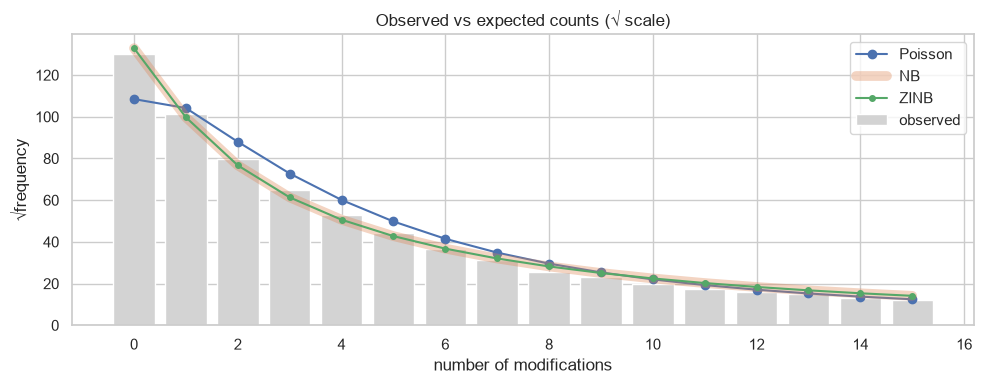

In [7]:
counts = np.arange(16)
obs = np.array([(train["n_mods"] == k).sum() for k in counts])
pois_exp = np.array([stats.poisson.pmf(k, poisson.fittedvalues).sum() for k in counts])
n_param = 1 / alpha
nb_exp = np.array([stats.nbinom.pmf(k, n_param, n_param / (n_param + mu_nb)).sum() for k in counts])
zinb_probs = zinb.predict(X, exog_infl=Z, offset=train["log_planned_years"].to_numpy(), which="prob", y_values=counts)
zinb_exp = np.asarray(zinb_probs).sum(axis=0)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(counts, np.sqrt(obs), color="lightgrey", label="observed")
ax.plot(counts, np.sqrt(pois_exp), marker="o", label="Poisson")
# NB drawn wide underneath: ZINB lands exactly on top of it, which is the point.
ax.plot(counts, np.sqrt(nb_exp), lw=7, alpha=0.35, color="C1", label="NB")
ax.plot(counts, np.sqrt(zinb_exp), marker="o", ms=4, color="C2", label="ZINB")
ax.set(xlabel="number of modifications", ylabel="√frequency", title="Observed vs expected counts (√ scale)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG + "02_rootogram.png", dpi=120); plt.show()

## 5. Interpreting the chosen model

Coefficients are on the log scale. exp(β) is a **rate ratio**: the multiplicative change in modifications per
planned year. The table shows the main contract-design variables from the NB model.

In [8]:
def rate_ratios(res, keep):
    ci = res.conf_int()
    out = pd.DataFrame({"rate_ratio": np.exp(res.params), "ci_low": np.exp(ci[0]), "ci_high": np.exp(ci[1]),
                        "p": res.pvalues})
    return out[out.index.str.contains(keep)].round(3)

rate_ratios(nb, "pricing|competition|single_offer|september|final_two|log_ceiling|award_kind|small_business")

,rate_ratio,ci_low,ci_high,p
"C(pricing, Treatment('firm_fixed'))[T.cost_reimbursement]",1.143,1.099,1.189,0.000
"C(pricing, Treatment('firm_fixed'))[T.fixed_other]",1.170,1.028,1.332,0.017
"C(pricing, Treatment('firm_fixed'))[T.time_materials]",1.553,1.499,1.609,0.000
"C(competition, Treatment('full_open'))[T.not_competed]",1.096,1.057,1.135,0.000
"C(competition, Treatment('full_open'))[T.other]",1.159,0.564,2.383,0.688
"C(competition, Treatment('full_open'))[T.set_aside]",1.089,1.051,1.128,0.000
"C(competition, Treatment('full_open'))[T.simplified]",1.474,1.413,1.538,0.000
"C(award_kind, Treatment('delivery_order'))[T.bpa_call]",1.153,1.101,1.206,0.000
"C(award_kind, Treatment('delivery_order'))[T.definitive_contract]",1.379,1.325,1.435,0.000
"C(award_kind, Treatment('delivery_order'))[T.purchase_order]",0.680,0.652,0.709,0.000


## 6. Diagnostics on the NB model

- Pearson residuals vs fitted values (no strong trend expected).
- Cook's distance to find awards with outsized influence.
- Out-of-sample check on the FY2022-23 cohort: mean predicted vs observed by decile of prediction.

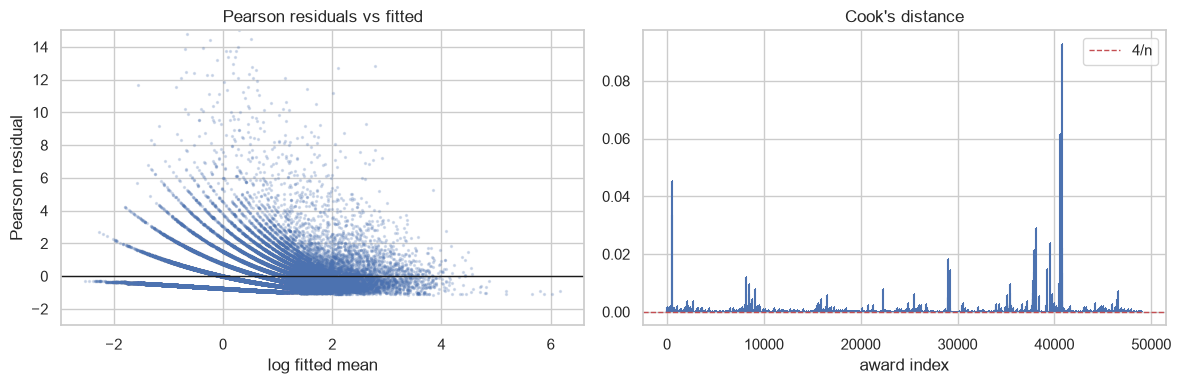

,award_id_piid,n_mods,planned_days,pricing,cooks
52362,DTFAWA16D00041CALL0002,251,3480,firm_fixed,0.092796
52173,DTFAWA15D00049CALL0004,113,363,firm_fixed,0.061454
534,0002,265,3479,firm_fixed,0.045402
533,0002,90,3479,firm_fixed,0.033635
49648,DTFAWA11A00046CALL0002,53,5,time_materials,0.029008


In [9]:
infl = nb.get_influence(observed=False)
cooks = infl.cooks_distance[0]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(np.log(nb.fittedvalues), nb.resid_pearson, s=2, alpha=0.2)
ax[0].axhline(0, color="k", lw=1)
ax[0].set(xlabel="log fitted mean", ylabel="Pearson residual", title="Pearson residuals vs fitted", ylim=(-3, 15))
ax[1].stem(np.arange(len(cooks)), cooks, markerfmt=",", basefmt=" ")
ax[1].axhline(4 / len(cooks), color="r", lw=1, ls="--", label="4/n")
ax[1].set(title="Cook's distance", xlabel="award index"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG + "02_nb_diagnostics.png", dpi=120); plt.show()

top = train.assign(cooks=cooks).nlargest(5, "cooks")[["award_id_piid", "n_mods", "planned_days", "pricing", "cooks"]]
top

The most influential awards are long contracts with hundreds of modifications. To check they are not driving
the conclusions, refit without the top 0.1% by Cook's distance and compare the key rate ratios.

In [10]:
keep = cooks < np.quantile(cooks, 0.999)
nb_trim = smf.glm(formula, data=train[keep], family=sm.families.NegativeBinomial(alpha=alpha),
                  offset=train.loc[keep, "log_planned_years"]).fit()
cmp = pd.DataFrame({"full": np.exp(nb.params), "without_top_0.1%": np.exp(nb_trim.params)})
cmp[cmp.index.str.contains("pricing|single_offer|september|final_two")].round(3)

,full,without_top_0.1%
"C(pricing, Treatment('firm_fixed'))[T.cost_reimbursement]",1.143,1.157
"C(pricing, Treatment('firm_fixed'))[T.fixed_other]",1.170,1.194
"C(pricing, Treatment('firm_fixed'))[T.time_materials]",1.553,1.592
single_offer,1.144,1.157
september,0.929,0.939
final_two_weeks,1.075,1.068


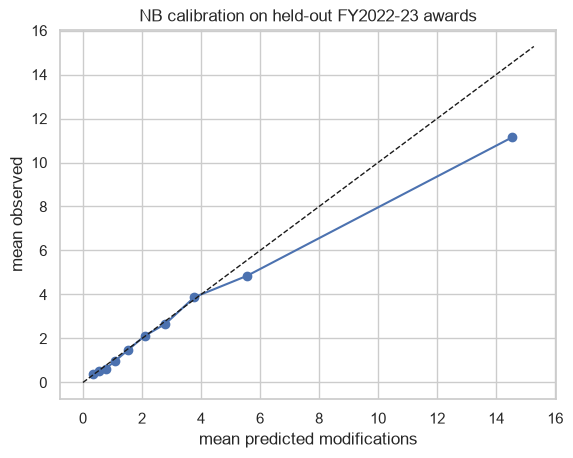

held-out mean predicted 3.30 vs observed 2.86


In [11]:
# Out-of-sample calibration on the held-out FY2022-23 cohort. The model has no fixed effect for an unseen year,
# so score these awards as if they belonged to the latest training cohort (FY2021).
test_pred = nb.predict(test.assign(base_fiscal_year=2021), offset=test["log_planned_years"])
cal = (pd.DataFrame({"pred": test_pred, "obs": test["n_mods"]})
       .assign(decile=lambda d: pd.qcut(d["pred"], 10, labels=False, duplicates="drop"))
       .groupby("decile").mean())
plt.plot(cal["pred"], cal["obs"], marker="o")
lim = [0, cal.max().max() * 1.05]
plt.plot(lim, lim, "k--", lw=1)
plt.xlabel("mean predicted modifications"); plt.ylabel("mean observed")
plt.title("NB calibration on held-out FY2022-23 awards"); plt.show()
print(f"held-out mean predicted {test_pred.mean():.2f} vs observed {test['n_mods'].mean():.2f}")

## Findings

- **Poisson is clearly wrong here.** Pearson χ²/df ≈ 5.7, the Cameron-Trivedi test rejects equidispersion, and
  NB2 cuts AIC by ~70,000. With α ≈ 0.76, the variance at a mean of 3 modifications is about 10, not 3.
- **Zero inflation is not needed.** NB already reproduces the share of never-modified awards. ZINB's inflation
  part claims almost no probability mass, and AIC/BIC both prefer plain NB. The extra zeros came from
  overdispersion, not from a separate "never touched" population.
- **Contract design matters, holding size and length fixed.** Time-and-materials awards are modified ~55% more
  often per planned year than firm-fixed-price ones. Awards made under simplified acquisition procedures ~47% more.
  Single-offer awards ~14% more. Larger awards are modified more (rate ratio ≈ 1.43 per log-dollar).
- **The September rush is mixed.** Early-September awards are modified slightly *less* often (×0.93), but awards
  signed in the final two weeks of the fiscal year are modified ~7% more than other September awards.
- **Robustness.** Dropping the most influential 0.1% of awards barely moves the rate ratios. On the held-out
  FY2022-23 cohort the model over-predicts by ~15% (3.30 vs 2.86), consistent with these younger awards having
  less follow-up time and with the downward cohort trend in the year effects.